## Step 03: Fine-tuning and Experiments

**Goal:** fine-tune a pretrained Transformer so it ranks the correct answer first for each question, then compare several configurations.

**Method (bi-encoder + contrastive learning)**
- The **same Transformer encoder** turns a question and an answer into 768-number vectors (normalized). Similarity = cosine.
- **Loss: `MultipleNegativesRankingLoss`.** In each batch, a question's own answer is the positive. All *other* answers in the batch are negatives. Training pulls each question toward its answer and pushes it away from the rest.
- `NO_DUPLICATES` batch sampler: the same text never appears twice in a batch, so a true match is not treated as a negative.
- Input: question (with the model's query prefix if it has one). Output: a vector. At search time the nearest answer vector wins.

**Experiments (all selected on the validation split; test is untouched until Notebook 04)**
| Run | What changes | Question it answers |
|---|---|---|
| A | MiniLM-L6, 3 epochs | Does a small model fine-tune well enough? |
| B | BGE-base, 3 epochs | Main model |
| C | PubMedBERT, 3 epochs | Does a biomedical model beat a general one? |
| D | BGE-base, 1 epoch | How much do extra epochs help? |
| B + 512 | B evaluated with max length 512 | Does truncation (256 tokens) hurt? |

**Key hyperparameters:** epochs, learning rate 2e-5, batch size 32, warm-up 10% of steps, max sequence length 256, fp16 (half precision, faster on GPU).

## 1. Setup
**What it does:** imports the libraries, checks the GPU and creates the output folders.

In [1]:
import os, gc, json, shutil, time, math
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret found, continuing without it")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import datasets
from glob import glob
from pathlib import Path
from datasets import Dataset
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments)
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

# switch off the progress bars
datasets.disable_progress_bars()
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

ROOT = Path("/kaggle/working/healthcare-qa-assistant")
for folder in ["models", "results/metrics", "results/plots"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

Device: cuda


/tmp/ipykernel_675/3144594422.py:20: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import MultipleNegativesRankingLoss
/tmp/ipykernel_675/3144594422.py:21: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


## 2. Load the data
Finds `train.csv` and `val.csv` from the output of Notebook 01.

In [2]:
def locate(rel_path):
    # working folder first, then attached inputs (newest file wins)
    local = ROOT / rel_path
    found = [Path(p) for p in glob(f"/kaggle/input/**/{rel_path}", recursive=True)]
    if local.exists():
        return local
    if found:
        return max(found, key=lambda p: p.stat().st_mtime)
    raise FileNotFoundError(f"{rel_path} not found. Attach the output of the earlier notebook as an input.")

def load_split(name):
    path = locate(f"data/processed/{name}.csv")
    print(f"{name}: {path}")
    return pd.read_csv(path).rename(columns={"Question": "question", "Answer": "answer"})


train = load_split("train")
val = load_split("val")
print(len(train), len(val))

train: /kaggle/working/healthcare-qa-assistant/data/processed/train.csv
val: /kaggle/working/healthcare-qa-assistant/data/processed/val.csv
12624 1585


## 3. Validation search task and metrics
Same task as Notebook 02: corpus = unique validation answers, queries = validation questions.
- **Recall@k:** correct answer is in the top k.
- **MRR:** average of 1/rank (rewards ranking it first). We pick the best run by MRR.

In [3]:
corpus = val["answer"].drop_duplicates().tolist()
answer_to_id = {a: i for i, a in enumerate(corpus)}
queries = val["question"].tolist()
gold = val["answer"].map(answer_to_id).values
print(len(queries), "queries |", len(corpus), "answers")

def positions(scores, gold):
    # rank of the correct answer for each query (1 = best)
    gold_score = scores[np.arange(len(gold)), gold]
    return (scores > gold_score[:, None]).sum(axis=1) + 1

def evaluate(scores, gold, ks=(1, 5, 10)):
    position = positions(scores, gold)
    result = {f"Recall@{k}": round(float((position <= k).mean()), 4) for k in ks}
    result["MRR"] = round(float((1 / position).mean()), 4)
    return result


def retrieval_scores(model, prefix, max_len=None):
    if max_len:
        model.max_seq_length = max_len
    doc_emb = model.encode(corpus, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    q_emb = model.encode([prefix + q for q in queries], batch_size=64,
                         normalize_embeddings=True, show_progress_bar=False)
    return q_emb @ doc_emb.T

1585 queries | 1572 answers


## 4. Experiment settings
`prefix` is the instruction BGE expects before a query (queries only, never answers).

In [4]:
BGE_PREFIX = "Represent this sentence for searching relevant passages: "

CONFIGS = {
    "A_minilm_3ep":     dict(model="sentence-transformers/all-MiniLM-L6-v2", prefix="",         epochs=3, lr=2e-5, batch=32, max_len=256),
    "B_bge_3ep":        dict(model="BAAI/bge-base-en-v1.5",                   prefix=BGE_PREFIX, epochs=3, lr=2e-5, batch=32, max_len=256),
    "C_pubmedbert_3ep": dict(model="NeuML/pubmedbert-base-embeddings",        prefix="",         epochs=3, lr=2e-5, batch=32, max_len=256),
    "D_bge_1ep":        dict(model="BAAI/bge-base-en-v1.5",                   prefix=BGE_PREFIX, epochs=1, lr=2e-5, batch=32, max_len=256),
}
RUN = list(CONFIGS)
print(RUN)

['A_minilm_3ep', 'B_bge_3ep', 'C_pubmedbert_3ep', 'D_bge_1ep']


## 5. Training function
1. Load the pretrained model and set the maximum input length.
2. Build pairs: **anchor** = question (with prefix), **positive** = its answer.
3. Train with `MultipleNegativesRankingLoss`. Warm-up steps are 10% of the total steps; the learning rate then decays linearly.
4. Return the model and its training-loss history.

In [5]:
def train_model(tag, cfg):
    model = SentenceTransformer(cfg["model"], device=device)
    model.max_seq_length = cfg["max_len"]

    train_ds = Dataset.from_dict({
        "anchor": [cfg["prefix"] + q for q in train["question"]],
        "positive": train["answer"].tolist(),
    })
    loss = MultipleNegativesRankingLoss(model)

    total_steps = math.ceil(len(train_ds) / cfg["batch"]) * cfg["epochs"]
    args = SentenceTransformerTrainingArguments(
        output_dir=str(ROOT / "models" / "checkpoints" / tag),
        num_train_epochs=cfg["epochs"],
        per_device_train_batch_size=cfg["batch"],
        learning_rate=cfg["lr"],
        warmup_steps=int(0.1 * total_steps),
        fp16=torch.cuda.is_available(),
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        save_strategy="no",
        logging_steps=50,
        report_to="none",
        seed=42,
    )
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=train_ds, loss=loss)

    start = time.time()
    trainer.train()
    minutes = round((time.time() - start) / 60, 1)
    return model, trainer, minutes

## 6. Zero-shot reference
Scores of the same base models **before** fine-tuning, on the same validation task. This is what fine-tuning must beat.

In [6]:
zero_rows = []
for model_id in sorted({c["model"] for c in CONFIGS.values()}):
    prefix = next(c["prefix"] for c in CONFIGS.values() if c["model"] == model_id)
    m = SentenceTransformer(model_id, device=device)
    zero_rows.append({"run": "zero-shot " + model_id.split("/")[-1], "model": model_id,
                      **evaluate(retrieval_scores(m, prefix), gold)})
    del m
    gc.collect()
    torch.cuda.empty_cache()

pd.DataFrame(zero_rows)

,run,model,Recall@1,Recall@5,Recall@10,MRR
0,zero-shot bge-base-en-v1.5,BAAI/bge-base-en-v1.5,0.8631,0.9615,0.9678,0.9077
1,zero-shot pubmedbert-base-embeddings,NeuML/pubmedbert-base-embeddings,0.7615,0.9476,0.9653,0.8468
2,zero-shot all-MiniLM-L6-v2,sentence-transformers/all-MiniLM-L6-v2,0.7842,0.9369,0.9533,0.8547


## 7. Run the experiments
Each run trains, evaluates on validation, and saves the model. The loss history is kept for the plot.

In [7]:
candidates, histories = [], {}

for tag in RUN:
    cfg = CONFIGS[tag]
    print(f"\n=== {tag} ===")
    model, trainer, minutes = train_model(tag, cfg)

    metrics = evaluate(retrieval_scores(model, cfg["prefix"]), gold)
    path = str(ROOT / "models" / tag)
    model.save(path)

    candidates.append({"run": tag, "model": cfg["model"], "epochs": cfg["epochs"], "lr": cfg["lr"],
                       "batch": cfg["batch"], "max_len": cfg["max_len"], "infer_max_len": cfg["max_len"],
                       "train_min": minutes, **metrics, "path": path, "prefix": cfg["prefix"]})
    histories[tag] = [x["loss"] for x in trainer.state.log_history if "loss" in x]
    print(tag, metrics, f"({minutes} min)")

    del model, trainer
    gc.collect()
    torch.cuda.empty_cache()


=== A_minilm_3ep ===


Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.236857
100,0.116545
150,0.088343
200,0.066804
250,0.063193
300,0.047872
350,0.048571
400,0.043804
450,0.040416
500,0.033364


A_minilm_3ep {'Recall@1': 0.9211, 'Recall@5': 0.9804, 'Recall@10': 0.9893, 'MRR': 0.9477} (3.4 min)

=== B_bge_3ep ===


...

C_pubmedbert_3ep {'Recall@1': 0.9464, 'Recall@5': 0.9886, 'Recall@10': 0.9943, 'MRR': 0.9662} (17.1 min)

=== D_bge_1ep ===


Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.247315
100,0.065121
150,0.050467


D_bge_1ep {'Recall@1': 0.9325, 'Recall@5': 0.9823, 'Recall@10': 0.9924, 'MRR': 0.9546} (5.9 min)


## 8. Extra experiment: longer input at search time
Run B was trained with a 256-token limit. Here the same model reads up to 512 tokens at search time, to see whether truncation hurts. No retraining needed.

In [8]:
base_run = next((c for c in candidates if c["run"] == "B_bge_3ep"), None)
if base_run is not None:
    m = SentenceTransformer(base_run["path"], device=device)
    metrics = evaluate(retrieval_scores(m, base_run["prefix"], max_len=512), gold)
    candidates.append({**base_run, "run": "B_bge_3ep + inference max_len 512",
                       "infer_max_len": 512, "train_min": 0.0, **metrics})
    print(metrics)
    del m
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("Run B not in RUN, skipping")

{'Recall@1': 0.9394, 'Recall@5': 0.9874, 'Recall@10': 0.9943, 'MRR': 0.9608}


## 9. Results, plots, and the final model
- The table goes into the report (experiments section).
- The best candidate by validation MRR is copied to `models/final`. All other saved models and checkpoints are deleted to keep the output small.
- `final_model.json` records the settings Notebook 04 and the app need (model, query prefix, max length).

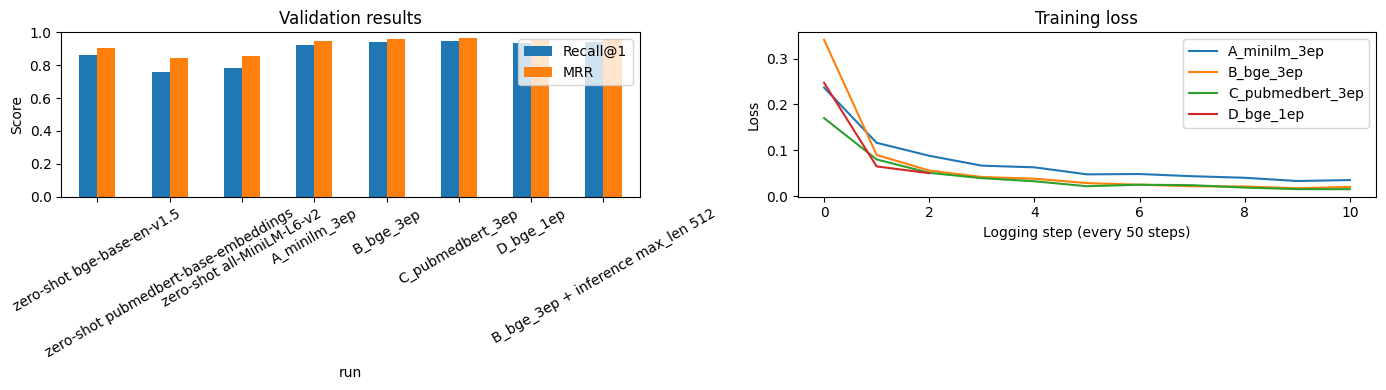

Best: C_pubmedbert_3ep | MRR 0.9662 | Recall@1 0.9464
{'run': 'C_pubmedbert_3ep', 'model_id': 'NeuML/pubmedbert-base-embeddings', 'prefix': '', 'max_len': 256, 'val_MRR': 0.9662, 'val_Recall@1': 0.9464}


,run,model,Recall@1,Recall@5,Recall@10,MRR,epochs,lr,batch,max_len,infer_max_len,train_min
0,zero-shot bge-base-en-v1.5,BAAI/bge-base-en-v1.5,0.8631,0.9615,0.9678,0.9077,NaN,NaN,NaN,NaN,NaN,NaN
1,zero-shot pubmedbert-base-embeddings,NeuML/pubmedbert-base-embeddings,0.7615,0.9476,0.9653,0.8468,NaN,NaN,NaN,NaN,NaN,NaN
2,zero-shot all-MiniLM-L6-v2,sentence-transformers/all-MiniLM-L6-v2,0.7842,0.9369,0.9533,0.8547,NaN,NaN,NaN,NaN,NaN,NaN
3,A_minilm_3ep,sentence-transformers/all-MiniLM-L6-v2,0.9211,0.9804,0.9893,0.9477,3.0,0.00002,32.0,256.0,256.0,3.4
4,B_bge_3ep,BAAI/bge-base-en-v1.5,0.9382,0.9868,0.9943,0.9601,3.0,0.00002,32.0,256.0,256.0,17.7
5,C_pubmedbert_3ep,NeuML/pubmedbert-base-embeddings,0.9464,0.9886,0.9943,0.9662,3.0,0.00002,32.0,256.0,256.0,17.1
6,D_bge_1ep,BAAI/bge-base-en-v1.5,0.9325,0.9823,0.9924,0.9546,1.0,0.00002,32.0,256.0,256.0,5.9
7,B_bge_3ep + inference max_len 512,BAAI/bge-base-en-v1.5,0.9394,0.9874,0.9943,0.9608,3.0,0.00002,32.0,256.0,512.0,0.0


In [9]:
internal = ["path", "prefix"]
table = pd.concat([pd.DataFrame(zero_rows), pd.DataFrame(candidates).drop(columns=internal)], ignore_index=True)
table.to_csv(ROOT / "results/metrics/experiments.csv", index=False)

# plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
table.set_index("run")[["Recall@1", "MRR"]].plot(kind="bar", ax=axes[0])
axes[0].set(title="Validation results", ylabel="Score", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=30)
for tag, losses in histories.items():
    axes[1].plot(losses, label=tag)
axes[1].set(title="Training loss", xlabel="Logging step (every 50 steps)", ylabel="Loss")
axes[1].legend()
plt.tight_layout()
plt.savefig(ROOT / "results/plots/experiments.png", dpi=150, bbox_inches="tight")
plt.show()

# pick the best candidate by validation MRR
best = max(candidates, key=lambda r: r["MRR"])
print("Best:", best["run"], "| MRR", best["MRR"], "| Recall@1", best["Recall@1"])

final_dir = ROOT / "models" / "final"
if final_dir.exists():
    shutil.rmtree(final_dir)
shutil.copytree(best["path"], final_dir)
for d in (ROOT / "models").iterdir():
    if d.is_dir() and d.name != "final":
        shutil.rmtree(d)

final_info = {"run": best["run"], "model_id": best["model"], "prefix": best["prefix"],
              "max_len": best["infer_max_len"], "val_MRR": best["MRR"], "val_Recall@1": best["Recall@1"]}
with open(ROOT / "results/metrics/final_model.json", "w") as f:
    json.dump(final_info, f, indent=2)
print(final_info)

table